# **Import libraries**

In [1]:
import dask.dataframe as dd
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from statsmodels.tsa.seasonal import STL
import seaborn as sns
import numpy as np

/usr/local/lib/python3.10/dist-packages/dask/dataframe/__init__.py:42: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


# **Creating Dataframe**

In [2]:
sector_df = pd.read_csv('/content/drive/MyDrive/RND/OperationsBridge/flightsector2.csv', low_memory=False)
print(sector_df.head())

   BOOKING_ID PRODUCT_CODE  ITEM_NO  SECTOR_NO  LEG_NO BOOKED_DATE DIRECTION  \
0       10006          FLT      1.0        1.0     1.0  2018-11-15         O   
1       10007          FLT      1.0        2.0     2.0  2018-11-15         I   
2       10007          FLT      1.0        1.0     1.0  2018-11-15         O   
3       10006          FLT      1.0        2.0     1.0  2018-11-15         O   
4       10006          FLT      1.0        3.0     2.0  2018-11-15         I   

  AIRLINE  DEP  DES   DEP_DATE   DES_DATE BOOKING_CLASS     CABIN_CLASS  \
0      LH  LHR  MUC  01-SEP-19  01-SEP-19             K         Economy   
1      BA  DEL  LHR  29-AUG-19  29-AUG-19             V         Economy   
2      BA  LHR  DEL  20-AUG-19  20-AUG-19             N         Economy   
3      LH  MUC  DEL  01-SEP-19  01-SEP-19             K         Economy   
4      LH  DEL  FRA  09-SEP-19  09-SEP-19             N  PremiumEconomy   

  OPERATING_AIRLINE  
0                LH  
1                BA  
2 

In [3]:
bookings_df = pd.read_csv('/content/drive/MyDrive/RND/OperationsBridge/flightbookings2.csv', low_memory=False)
print(bookings_df.head())

   BOOKING_ID PRODUCT_CODE  ITEM_NO  BOOKING_STATUS  OPTION_STATUS  \
0       10006          FLT      1.0          1000.0          400.0   
1       10007          FLT      1.0          1000.0          400.0   
2       10012          FLT      1.0          1000.0          400.0   
3       10013          FLT      1.0          1000.0          400.0   
4       10014          FLT      1.0          1000.0          400.0   

   BOOKING_ITEM_STATUS BOOKED_DATE  FROM_DATE  ADULT  CHILD  ...  CRS  \
0               1000.0  2018-11-15  01-SEP-19    2.0    0.0  ...  TPU   
1               1000.0  2018-11-15  20-AUG-19    2.0    0.0  ...  TPU   
2               1000.0  2018-11-16  20-AUG-19    2.0    0.0  ...  TPU   
3               1000.0  2018-11-19  01-JAN-19    2.0    0.0  ...  TPU   
4               1000.0  2018-11-19  19-OCT-19    2.0    0.0  ...  TPU   

   ADT_COST  CHD_COST  INF_COST ADT_TAX_COST  CHD_TAX_COST  INF_TAX_COST  \
0      83.0       0.0       0.0       329.54           0.0      

# **Feature Selection**

In [4]:
columns_to_remove = ['PRODUCT_CODE', 'OPERATING_AIRLINE']
sector_df.drop(columns=columns_to_remove, inplace=True)

print(sector_df.head())

   BOOKING_ID  ITEM_NO  SECTOR_NO  LEG_NO BOOKED_DATE DIRECTION AIRLINE  DEP  \
0       10006      1.0        1.0     1.0  2018-11-15         O      LH  LHR   
1       10007      1.0        2.0     2.0  2018-11-15         I      BA  DEL   
2       10007      1.0        1.0     1.0  2018-11-15         O      BA  LHR   
3       10006      1.0        2.0     1.0  2018-11-15         O      LH  MUC   
4       10006      1.0        3.0     2.0  2018-11-15         I      LH  DEL   

   DES   DEP_DATE   DES_DATE BOOKING_CLASS     CABIN_CLASS  
0  MUC  01-SEP-19  01-SEP-19             K         Economy  
1  LHR  29-AUG-19  29-AUG-19             V         Economy  
2  DEL  20-AUG-19  20-AUG-19             N         Economy  
3  DEL  01-SEP-19  01-SEP-19             K         Economy  
4  FRA  09-SEP-19  09-SEP-19             N  PremiumEconomy  


In [5]:
columns_to_remove = ['PRODUCT_CODE', 'BOOKING_STATUS', 'OPTION_STATUS', 'BOOKING_ITEM_STATUS', 'CURRENCY_IN_CONTRACT' , 'ADT_COST' ,'CHD_COST','INF_COST','ADT_PRICE','CHD_PRICE','INF_PRICE', 'COST', 'COST_IN_CONTRACT', 'TOTAL_COST', 'TOTAL_COST_IN_CONTRACT', 'ADT_TAX_COST', 'CHD_TAX_COST', 'INF_TAX_COST']
bookings_df.drop(columns=columns_to_remove, inplace=True)

print(bookings_df.head())

   BOOKING_ID  ITEM_NO BOOKED_DATE  FROM_DATE  ADULT  CHILD  INFANT    PRICE  \
0       10006      1.0  2018-11-15  01-SEP-19    2.0    0.0     0.0   833.38   
1       10007      1.0  2018-11-15  20-AUG-19    2.0    0.0     0.0  1487.94   
2       10012      1.0  2018-11-16  20-AUG-19    2.0    0.0     0.0  2043.94   
3       10013      1.0  2018-11-19  01-JAN-19    2.0    0.0     0.0  1267.64   
4       10014      1.0  2018-11-19  19-OCT-19    2.0    0.0     0.0  1116.78   

   TOTAL_PRICE FARE_TYPE  CRS  
0       833.38       PUB  TPU  
1      1487.94       PUB  TPU  
2      2043.94       PVT  TPU  
3      1267.64       PUB  TPU  
4      1116.78       PUB  TPU  


In [6]:
date_columns_sec = ['DEP_DATE', 'DES_DATE', 'BOOKED_DATE']
date_columns_book = ['BOOKED_DATE', 'FROM_DATE']
for col in date_columns_sec:
  sector_df[col] = pd.to_datetime(sector_df[col])

for col in date_columns_book:
  bookings_df[col] = pd.to_datetime(bookings_df[col])

print(sector_df.head())
print(bookings_df.head())


<ipython-input-6-07a88d6b6c83>:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sector_df[col] = pd.to_datetime(sector_df[col])
<ipython-input-6-07a88d6b6c83>:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sector_df[col] = pd.to_datetime(sector_df[col])
<ipython-input-6-07a88d6b6c83>:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  bookings_df[col] = pd.to_datetime(bookings_df[col])


   BOOKING_ID  ITEM_NO  SECTOR_NO  LEG_NO BOOKED_DATE DIRECTION AIRLINE  DEP  \
0       10006      1.0        1.0     1.0  2018-11-15         O      LH  LHR   
1       10007      1.0        2.0     2.0  2018-11-15         I      BA  DEL   
2       10007      1.0        1.0     1.0  2018-11-15         O      BA  LHR   
3       10006      1.0        2.0     1.0  2018-11-15         O      LH  MUC   
4       10006      1.0        3.0     2.0  2018-11-15         I      LH  DEL   

   DES   DEP_DATE   DES_DATE BOOKING_CLASS     CABIN_CLASS  
0  MUC 2019-09-01 2019-09-01             K         Economy  
1  LHR 2019-08-29 2019-08-29             V         Economy  
2  DEL 2019-08-20 2019-08-20             N         Economy  
3  DEL 2019-09-01 2019-09-01             K         Economy  
4  FRA 2019-09-09 2019-09-09             N  PremiumEconomy  
   BOOKING_ID  ITEM_NO BOOKED_DATE  FROM_DATE  ADULT  CHILD  INFANT    PRICE  \
0       10006      1.0  2018-11-15 2019-09-01    2.0    0.0     0.0   833

# **Feature Engineering**

In [7]:
# Calculate the difference between BOOKED_DATE and DEP_DATE in sector_df
sector_df['DAYS_IN_BETWEEN'] = (sector_df['DEP_DATE'] - sector_df['BOOKED_DATE']).dt.days

# Calculate the difference between BOOKED_DATE and FROM_DATE in bookings_df
bookings_df['DAYS_IN_BETWEEN'] = (bookings_df['FROM_DATE'] - bookings_df['BOOKED_DATE']).dt.days

print(sector_df.head())
print(bookings_df.head())


   BOOKING_ID  ITEM_NO  SECTOR_NO  LEG_NO BOOKED_DATE DIRECTION AIRLINE  DEP  \
0       10006      1.0        1.0     1.0  2018-11-15         O      LH  LHR   
1       10007      1.0        2.0     2.0  2018-11-15         I      BA  DEL   
2       10007      1.0        1.0     1.0  2018-11-15         O      BA  LHR   
3       10006      1.0        2.0     1.0  2018-11-15         O      LH  MUC   
4       10006      1.0        3.0     2.0  2018-11-15         I      LH  DEL   

   DES   DEP_DATE   DES_DATE BOOKING_CLASS     CABIN_CLASS  DAYS_IN_BETWEEN  
0  MUC 2019-09-01 2019-09-01             K         Economy              290  
1  LHR 2019-08-29 2019-08-29             V         Economy              287  
2  DEL 2019-08-20 2019-08-20             N         Economy              278  
3  DEL 2019-09-01 2019-09-01             K         Economy              290  
4  FRA 2019-09-09 2019-09-09             N  PremiumEconomy              298  
   BOOKING_ID  ITEM_NO BOOKED_DATE  FROM_DATE  ADUL

In [8]:
print(sector_df.shape)
print(bookings_df.shape)

(3818178, 14)
(1345474, 12)


In [9]:
# prompt: convert the FROM_DATE to YEAR, MONTH, DAY

sector_df['DEP_YEAR'] = sector_df['DEP_DATE'].dt.year
sector_df['DEP_MONTH'] = sector_df['DEP_DATE'].dt.month
sector_df['DEP_DAY'] = sector_df['DEP_DATE'].dt.day

sector_df['DES_YEAR'] = sector_df['DES_DATE'].dt.year
sector_df['DES_MONTH'] = sector_df['DES_DATE'].dt.month
sector_df['DES_DAY'] = sector_df['DES_DATE'].dt.day

print(sector_df.head())


   BOOKING_ID  ITEM_NO  SECTOR_NO  LEG_NO BOOKED_DATE DIRECTION AIRLINE  DEP  \
0       10006      1.0        1.0     1.0  2018-11-15         O      LH  LHR   
1       10007      1.0        2.0     2.0  2018-11-15         I      BA  DEL   
2       10007      1.0        1.0     1.0  2018-11-15         O      BA  LHR   
3       10006      1.0        2.0     1.0  2018-11-15         O      LH  MUC   
4       10006      1.0        3.0     2.0  2018-11-15         I      LH  DEL   

   DES   DEP_DATE   DES_DATE BOOKING_CLASS     CABIN_CLASS  DAYS_IN_BETWEEN  \
0  MUC 2019-09-01 2019-09-01             K         Economy              290   
1  LHR 2019-08-29 2019-08-29             V         Economy              287   
2  DEL 2019-08-20 2019-08-20             N         Economy              278   
3  DEL 2019-09-01 2019-09-01             K         Economy              290   
4  FRA 2019-09-09 2019-09-09             N  PremiumEconomy              298   

   DEP_YEAR  DEP_MONTH  DEP_DAY  DES_YEAR  D

# **Getting the most occurring combinations**

In [10]:
# # Group the DataFrame by the 'ADULT', 'CHILD', and 'INFANT' columns and count the occurrences
# combination_counts = bookings_df.groupby(['ADULT', 'CHILD', 'INFANT']).size().reset_index(name='COUNT')

# # Sort the combinations by count in descending order
# sorted_combinations = combination_counts.sort_values('COUNT', ascending=False)

# # Print the most occurring combinations
# print(sorted_combinations.head())


In [11]:
# import pandas as pd
# # Select the top 5 most occurring combinations
# top_5_combinations = sorted_combinations.head(5)

# # Create a list to store the filtered DataFrames
# filtered_dfs = []

# # Iterate over the top 5 combinations and filter the bookings_df
# for _, row in top_5_combinations.iterrows():
#     adult = row['ADULT']
#     child = row['CHILD']
#     infant = row['INFANT']
#     filtered_df = bookings_df[(bookings_df['ADULT'] == adult) &
#                                (bookings_df['CHILD'] == child) &
#                                (bookings_df['INFANT'] == infant)]
#     filtered_dfs.append(filtered_df)

# # Concatenate the filtered DataFrames into a new DataFrame
# filtered_bookings_df = pd.concat(filtered_dfs)
# # Print the head of the new DataFrame
# print(filtered_bookings_df.head())


In [12]:
# print(filtered_bookings_df.shape)

In [13]:
# # prompt: Now do same and find the top 5 most occurring values for DEP and DES. Create a new df with all the rows with these 5 combinations. This should be done on sector_df

# import pandas as pd
# # Group the DataFrame by the 'DEP' and 'DES' columns and count the occurrences
# combination_counts_dep_des = sector_df.groupby(['DEP', 'DES']).size().reset_index(name='COUNT')

# # Sort the combinations by count in descending order
# sorted_combinations_dep_des = combination_counts_dep_des.sort_values('COUNT', ascending=False)

# # Print the most occurring combinations
# print(sorted_combinations_dep_des.head())

# # Select the top 5 most occurring combinations
# top_5_combinations_dep_des = sorted_combinations_dep_des.head(20)

# # Create a list to store the filtered DataFrames
# filtered_dfs_dep_des = []

# # Iterate over the top 5 combinations and filter the sector_df
# for _, row in top_5_combinations_dep_des.iterrows():
#     dep = row['DEP']
#     des = row['DES']
#     filtered_df_dep_des = sector_df[(sector_df['DEP'] == dep) & (sector_df['DES'] == des)]
#     filtered_dfs_dep_des.append(filtered_df_dep_des)

# # Concatenate the filtered DataFrames into a new DataFrame
# filtered_sector_df = pd.concat(filtered_dfs_dep_des)

# # Print the head of the new DataFrame
# print(filtered_sector_df.head())

# print(filtered_sector_df.shape)


In [14]:
filtered_bookings_df = bookings_df
filtered_sector_df = sector_df

# **Data Cleaning**

**Booking data**

In [15]:
# prompt: check for duplicates in filtered_bookings

# Check for duplicates in filtered_bookings_df
duplicate_rows = filtered_bookings_df[filtered_bookings_df.duplicated()]
print("Number of duplicate rows:", duplicate_rows.shape[0])

# If you want to remove duplicates:
filtered_bookings_df = filtered_bookings_df.drop_duplicates()


Number of duplicate rows: 0


In [16]:

# Filter bookings_df to include only records with FROM_DATE after 2017
filtered_bookings_df = filtered_bookings_df[filtered_bookings_df['FROM_DATE'].dt.year > 2017]
print(filtered_bookings_df.head())


   BOOKING_ID  ITEM_NO BOOKED_DATE  FROM_DATE  ADULT  CHILD  INFANT    PRICE  \
0       10006      1.0  2018-11-15 2019-09-01    2.0    0.0     0.0   833.38   
1       10007      1.0  2018-11-15 2019-08-20    2.0    0.0     0.0  1487.94   
2       10012      1.0  2018-11-16 2019-08-20    2.0    0.0     0.0  2043.94   
3       10013      1.0  2018-11-19 2019-01-01    2.0    0.0     0.0  1267.64   
4       10014      1.0  2018-11-19 2019-10-19    2.0    0.0     0.0  1116.78   

   TOTAL_PRICE FARE_TYPE  CRS  DAYS_IN_BETWEEN  
0       833.38       PUB  TPU              290  
1      1487.94       PUB  TPU              278  
2      2043.94       PVT  TPU              277  
3      1267.64       PUB  TPU               43  
4      1116.78       PUB  TPU              334  


In [17]:
print(filtered_bookings_df.tail())

         BOOKING_ID  ITEM_NO BOOKED_DATE  FROM_DATE  ADULT  CHILD  INFANT  \
1345469      298389      8.0  2024-07-24 2024-10-07    2.0    0.0     0.0   
1345470      299683      1.0  2024-07-24 2024-12-16    2.0    0.0     0.0   
1345471      299679      2.0  2024-07-24 2024-10-15    2.0    0.0     0.0   
1345472      299198      6.0  2024-07-24 2025-07-12    4.0    0.0     0.0   
1345473      299693      5.0  2024-07-24 2024-09-26    2.0    0.0     0.0   

           PRICE  TOTAL_PRICE FARE_TYPE           CRS  DAYS_IN_BETWEEN  
1345469  2089.90      2089.90       ITX           TPU               75  
1345470  1998.00      1998.00       ITX           TPU              145  
1345471   622.10       622.10         L  Travelfusion               83  
1345472   380.48       380.48       PUB           TPU              353  
1345473  1101.06      1101.06       ITX           TPU               64  


In [18]:
print(filtered_bookings_df.shape)

(1345473, 12)


In [19]:
# prompt: convert all catergorical columns to numerical

from sklearn.preprocessing import LabelEncoder

# Identify categorical columns
categorical_cols = filtered_bookings_df.select_dtypes(include=['object']).columns

# Apply LabelEncoder to each categorical column
label_encoder = LabelEncoder()
for col in categorical_cols:
    filtered_bookings_df[col] = label_encoder.fit_transform(filtered_bookings_df[col])

print(filtered_bookings_df.head())


   BOOKING_ID  ITEM_NO BOOKED_DATE  FROM_DATE  ADULT  CHILD  INFANT    PRICE  \
0       10006      1.0  2018-11-15 2019-09-01    2.0    0.0     0.0   833.38   
1       10007      1.0  2018-11-15 2019-08-20    2.0    0.0     0.0  1487.94   
2       10012      1.0  2018-11-16 2019-08-20    2.0    0.0     0.0  2043.94   
3       10013      1.0  2018-11-19 2019-01-01    2.0    0.0     0.0  1267.64   
4       10014      1.0  2018-11-19 2019-10-19    2.0    0.0     0.0  1116.78   

   TOTAL_PRICE  FARE_TYPE  CRS  DAYS_IN_BETWEEN  
0       833.38          4    3              290  
1      1487.94          4    3              278  
2      2043.94          5    3              277  
3      1267.64          4    3               43  
4      1116.78          4    3              334  


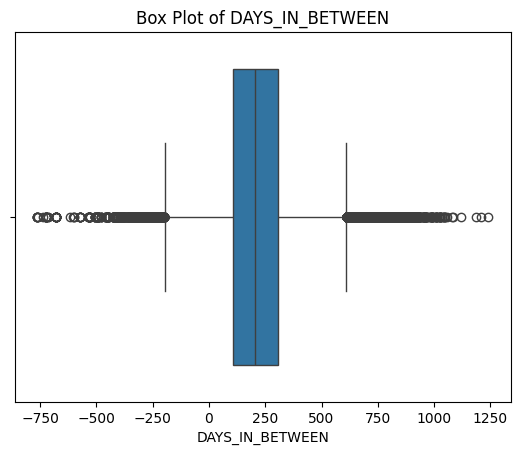

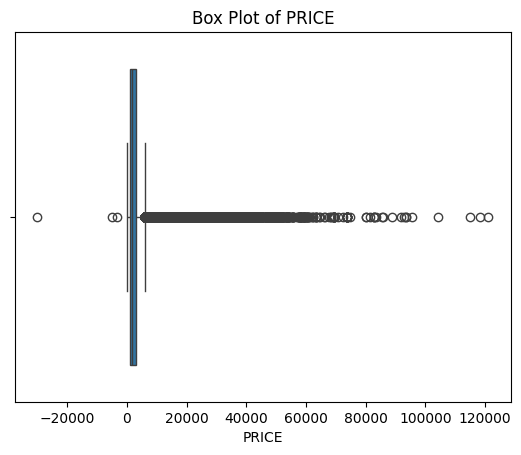

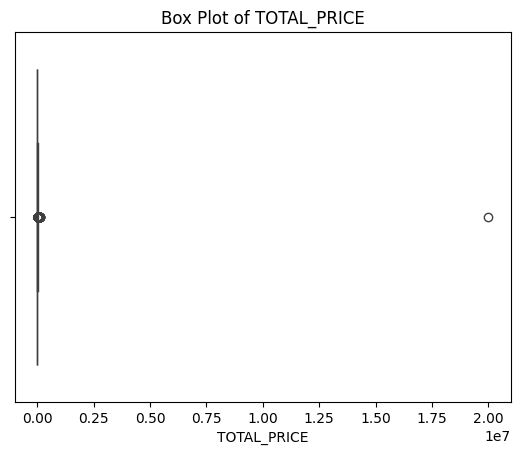

In [20]:
# prompt: boxplots to check for outliers

import matplotlib.pyplot as plt
# Create box plots for numerical columns to check for outliers
numerical_cols = ['DAYS_IN_BETWEEN', 'PRICE', 'TOTAL_PRICE']
for col in numerical_cols:
  plt.figure()
  sns.boxplot(x=filtered_bookings_df[col])
  plt.title(f'Box Plot of {col}')
  plt.show()


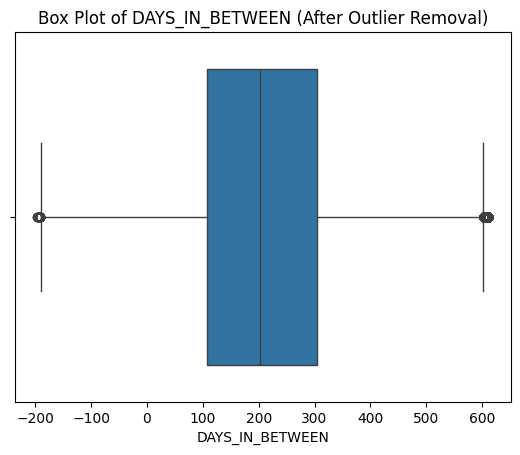

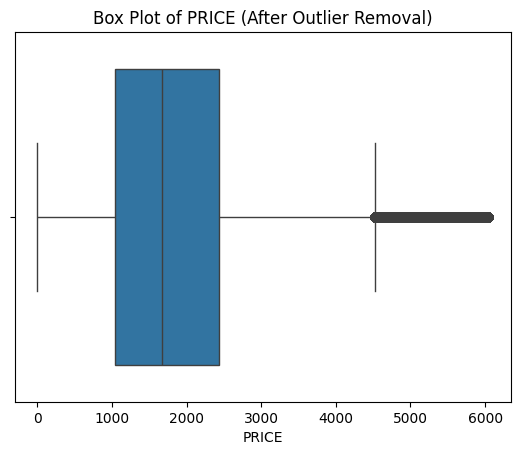

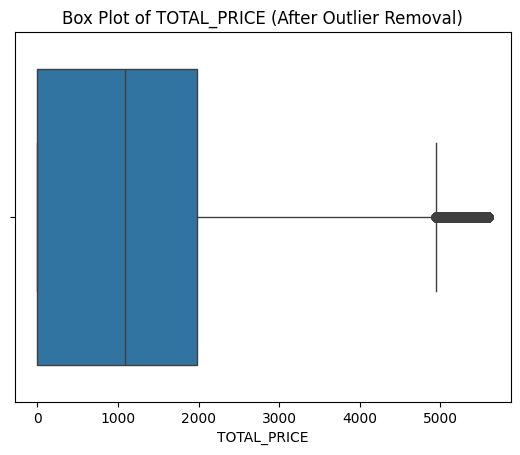

In [21]:
import matplotlib.pyplot as plt
# Calculate IQR for each numerical column
Q1 = filtered_bookings_df[numerical_cols].quantile(0.25)
Q3 = filtered_bookings_df[numerical_cols].quantile(0.75)
IQR = Q3 - Q1

# Define bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter out outliers
filtered_bookings_df = filtered_bookings_df[~((filtered_bookings_df[numerical_cols] < lower_bound) | (filtered_bookings_df[numerical_cols] > upper_bound)).any(axis=1)]

# Verify outlier removal
for col in numerical_cols:
  plt.figure()
  sns.boxplot(x=filtered_bookings_df[col])
  plt.title(f'Box Plot of {col} (After Outlier Removal)')
  plt.show()


In [22]:
# prompt: show this new df in csv

# filtered_bookings_df.to_csv('filtered_bookings.csv', index=False)


**Sector data**

Number of duplicate rows: 0
Missing values:
 BOOKING_ID            0
ITEM_NO               0
SECTOR_NO             0
LEG_NO                0
BOOKED_DATE           0
DIRECTION             0
AIRLINE               0
DEP                   0
DES                   0
DEP_DATE              0
DES_DATE              0
BOOKING_CLASS      1112
CABIN_CLASS        8286
DAYS_IN_BETWEEN       0
DEP_YEAR              0
DEP_MONTH             0
DEP_DAY               0
DES_YEAR              0
DES_MONTH             0
DES_DAY               0
dtype: int64


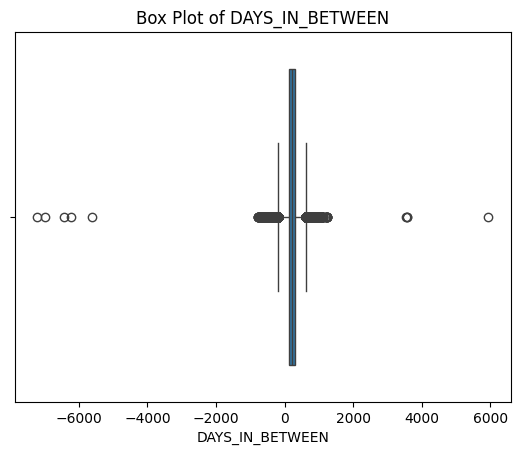

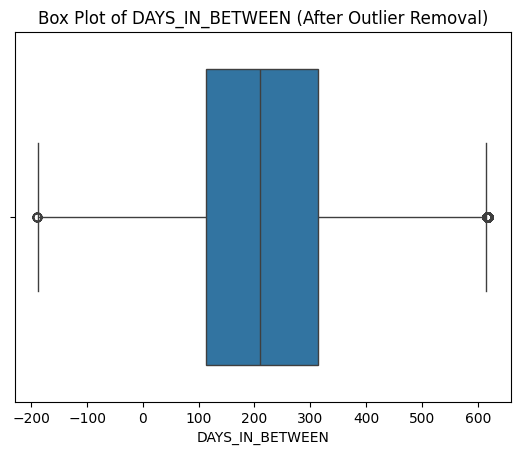

In [23]:
# prompt: check for duplicates, missing values, convert all catergorical features in to numerical ,remove outliers

import matplotlib.pyplot as plt
# Check for duplicates in filtered_sector_df
duplicate_rows_sec = filtered_sector_df[filtered_sector_df.duplicated()]
print("Number of duplicate rows:", duplicate_rows_sec.shape[0])

# If you want to remove duplicates:
filtered_sector_df = filtered_sector_df.drop_duplicates()

# Check for missing values
missing_values = filtered_sector_df.isnull().sum()
print("Missing values:\n", missing_values)

# Create box plots for numerical columns to check for outliers
numerical_cols_sec = ['DAYS_IN_BETWEEN']
for col in numerical_cols_sec:
  plt.figure()
  sns.boxplot(x=filtered_sector_df[col])
  plt.title(f'Box Plot of {col}')
  plt.show()

# Calculate IQR for each numerical column
Q1_sec = filtered_sector_df[numerical_cols_sec].quantile(0.25)
Q3_sec = filtered_sector_df[numerical_cols_sec].quantile(0.75)
IQR_sec = Q3_sec - Q1_sec

# Define bounds for outliers
lower_bound_sec = Q1_sec - 1.5 * IQR_sec
upper_bound_sec = Q3_sec + 1.5 * IQR_sec

# Filter out outliers
filtered_sector_df = filtered_sector_df[~((filtered_sector_df[numerical_cols_sec] < lower_bound_sec) | (filtered_sector_df[numerical_cols_sec] > upper_bound_sec)).any(axis=1)]

# Verify outlier removal
for col in numerical_cols_sec:
  plt.figure()
  sns.boxplot(x=filtered_sector_df[col])
  plt.title(f'Box Plot of {col} (After Outlier Removal)')
  plt.show()


In [24]:
# prompt: show the top 5 combinations after encoding

# Group the DataFrame by the encoded 'AIRLINE', 'DEP', and 'DES' columns and count the occurrences
combination_counts_sec = filtered_sector_df.groupby(['AIRLINE', 'DEP', 'DES']).size().reset_index(name='COUNT')

# Sort the combinations by count in descending order
sorted_combinations_sec = combination_counts_sec.sort_values('COUNT', ascending=False)

# Print the top 5 most occurring combinations after encoding
print(sorted_combinations_sec.head())


     AIRLINE  DEP  DES   COUNT
5703      EK  MLE  DXB  121799
5575      EK  DXB  MLE  113079
5563      EK  DXB  LHR   91113
5669      EK  LHR  DXB   90706
5686      EK  MAN  DXB   79973


In [25]:
# filtered_sector_df.to_csv('filtered_sector.csv', index=False)


In [26]:
print(filtered_bookings_df.shape)
print(filtered_sector_df.shape)

(1187322, 12)
(3785083, 20)


# **Connecting the dataframes**

In [27]:
# prompt: can you merge the two df using BOOKING_ID, BOOKED_DATE and FROM_DATE = DEP_DATE. get only the rows that are matching and remove everything else

import pandas as pd
# Merge the two DataFrames on the specified columns
merged_df = pd.merge(filtered_bookings_df, filtered_sector_df,
                     left_on=['BOOKING_ID', 'ITEM_NO'],
                     right_on=['BOOKING_ID', 'ITEM_NO'],
                     how='inner')

# Print the shape of the merged DataFrame
print(merged_df.shape)

# Print the head of the merged DataFrame
print(merged_df.head())


(3302383, 30)
   BOOKING_ID  ITEM_NO BOOKED_DATE_x  FROM_DATE  ADULT  CHILD  INFANT  \
0       10006      1.0    2018-11-15 2019-09-01    2.0    0.0     0.0   
1       10006      1.0    2018-11-15 2019-09-01    2.0    0.0     0.0   
2       10006      1.0    2018-11-15 2019-09-01    2.0    0.0     0.0   
3       10006      1.0    2018-11-15 2019-09-01    2.0    0.0     0.0   
4       10007      1.0    2018-11-15 2019-08-20    2.0    0.0     0.0   

     PRICE  TOTAL_PRICE  FARE_TYPE  ...   DES_DATE  BOOKING_CLASS  \
0   833.38       833.38          4  ... 2019-09-01              K   
1   833.38       833.38          4  ... 2019-09-01              K   
2   833.38       833.38          4  ... 2019-09-09              N   
3   833.38       833.38          4  ... 2019-09-09              Y   
4  1487.94      1487.94          4  ... 2019-08-29              V   

      CABIN_CLASS  DAYS_IN_BETWEEN_y DEP_YEAR DEP_MONTH DEP_DAY DES_YEAR  \
0         Economy                290     2019         9 

In [28]:
columns_to_remove = ['DAYS_IN_BETWEEN_x', 'BOOKED_DATE_y']
merged_df.drop(columns=columns_to_remove, inplace=True)

merged_df.rename(columns={'DAYS_IN_BETWEEN_y': 'DAYS_IN_BETWEEN', 'BOOKED_DATE_x': 'BOOKED_DATE'}, inplace=True)

print(merged_df.head())

   BOOKING_ID  ITEM_NO BOOKED_DATE  FROM_DATE  ADULT  CHILD  INFANT    PRICE  \
0       10006      1.0  2018-11-15 2019-09-01    2.0    0.0     0.0   833.38   
1       10006      1.0  2018-11-15 2019-09-01    2.0    0.0     0.0   833.38   
2       10006      1.0  2018-11-15 2019-09-01    2.0    0.0     0.0   833.38   
3       10006      1.0  2018-11-15 2019-09-01    2.0    0.0     0.0   833.38   
4       10007      1.0  2018-11-15 2019-08-20    2.0    0.0     0.0  1487.94   

   TOTAL_PRICE  FARE_TYPE  ...   DES_DATE  BOOKING_CLASS     CABIN_CLASS  \
0       833.38          4  ... 2019-09-01              K         Economy   
1       833.38          4  ... 2019-09-01              K         Economy   
2       833.38          4  ... 2019-09-09              N  PremiumEconomy   
3       833.38          4  ... 2019-09-09              Y         Economy   
4      1487.94          4  ... 2019-08-29              V         Economy   

  DAYS_IN_BETWEEN DEP_YEAR DEP_MONTH DEP_DAY DES_YEAR DES_MONT

Missing values:
 BOOKING_ID            0
ITEM_NO               0
BOOKED_DATE           0
FROM_DATE             0
ADULT                 0
CHILD                 0
INFANT                0
PRICE                 0
TOTAL_PRICE           0
FARE_TYPE             0
CRS                   0
SECTOR_NO             0
LEG_NO                0
DIRECTION             0
AIRLINE               0
DEP                   0
DES                   0
DEP_DATE              0
DES_DATE              0
BOOKING_CLASS      1052
CABIN_CLASS        7715
DAYS_IN_BETWEEN       0
DEP_YEAR              0
DEP_MONTH             0
DEP_DAY               0
DES_YEAR              0
DES_MONTH             0
DES_DAY               0
dtype: int64
Number of duplicate rows: 0


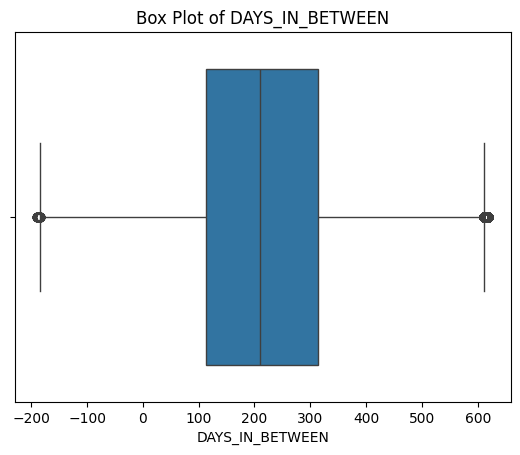

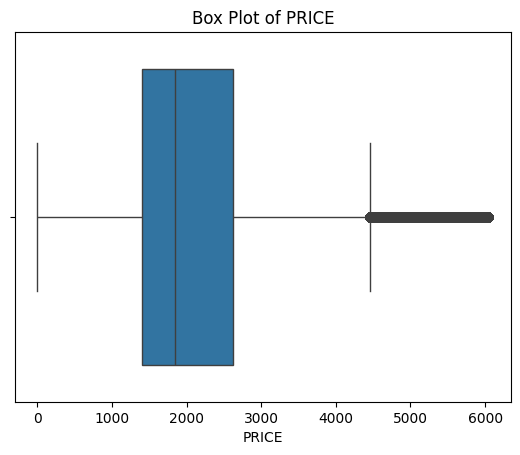

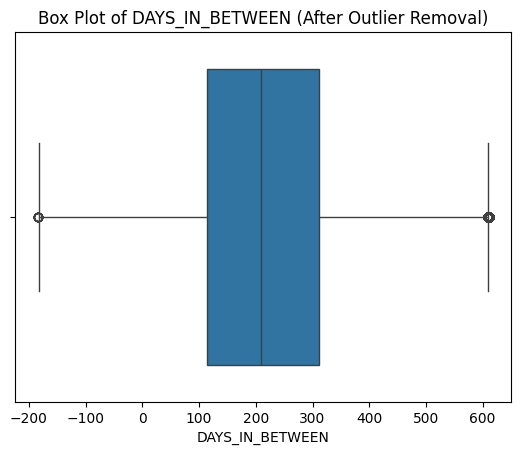

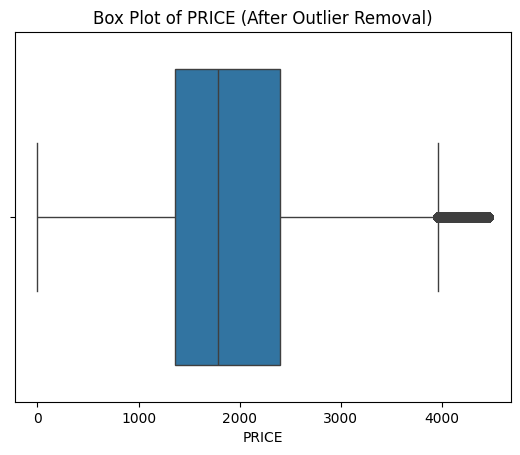

In [29]:
# prompt: clean this df (missing values, duplicates, outliers,standardize all catergorical features to use simple letters

import matplotlib.pyplot as plt
# **Handling Missing Values**

# Check for missing values
missing_values = merged_df.isnull().sum()
print("Missing values:\n", missing_values)

# Option 1: Drop rows with missing values
merged_df_dropped = merged_df.dropna()

# Option 2: Fill missing values (example with mean for numerical columns)
numerical_cols = merged_df.select_dtypes(include=['number']).columns
merged_df_filled = merged_df.fillna(merged_df[numerical_cols].mean())

# **Handling Duplicates**

# Check for duplicates
duplicate_rows = merged_df.duplicated().sum()
print("Number of duplicate rows:", duplicate_rows)

# Remove duplicates
merged_df_no_duplicates = merged_df.drop_duplicates()

# **Handling Outliers**

cols_for_outlier_removal = ['DAYS_IN_BETWEEN', 'PRICE']

# Create box plots for selected numerical columns to visualize outliers
for col in cols_for_outlier_removal:
    plt.figure()
    sns.boxplot(x=merged_df[col])
    plt.title(f'Box Plot of {col}')
    plt.show()

# Calculate IQR for each selected numerical column
Q1 = merged_df[cols_for_outlier_removal].quantile(0.25)
Q3 = merged_df[cols_for_outlier_removal].quantile(0.75)
IQR = Q3 - Q1

# Define bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter out outliers from selected columns
merged_df_no_outliers = merged_df[~((merged_df[cols_for_outlier_removal] < lower_bound) | (merged_df[cols_for_outlier_removal] > upper_bound)).any(axis=1)]

# Verify outlier removal
for col in cols_for_outlier_removal:
    plt.figure()
    sns.boxplot(x=merged_df_no_outliers[col])
    plt.title(f'Box Plot of {col} (After Outlier Removal)')
    plt.show()

In [30]:
# prompt: make the df so only FROM_DATE starts from 2021

# Filter merged_df to include only records with FROM_DATE after 2020
merged_df = merged_df[merged_df['FROM_DATE'].dt.year > 2020]
print(merged_df.head())


       BOOKING_ID  ITEM_NO BOOKED_DATE  FROM_DATE  ADULT  CHILD  INFANT  \
2871        10607      1.0  2019-05-22 2021-01-13    2.0    0.0     0.0   
2872        10607      1.0  2019-05-22 2021-01-13    2.0    0.0     0.0   
2955        10607      4.0  2019-05-22 2021-01-13    2.0    0.0     0.0   
2956        10607      4.0  2019-05-22 2021-01-13    2.0    0.0     0.0   
11673       11914      2.0  2019-07-06 2021-03-04    2.0    0.0     0.0   

        PRICE  TOTAL_PRICE  FARE_TYPE  ...   DES_DATE  BOOKING_CLASS  \
2871   1817.0       1817.0          3  ... 2021-01-24              N   
2872   1817.0       1817.0          3  ... 2021-01-14              N   
2955   1817.0       1817.0          3  ... 2021-01-14              N   
2956   1817.0       1817.0          3  ... 2021-01-25              N   
11673   305.9        305.9          3  ... 2021-03-04              O   

       CABIN_CLASS DAYS_IN_BETWEEN DEP_YEAR DEP_MONTH DEP_DAY DES_YEAR  \
2871       ECONOMY             612     202

In [31]:
# prompt: remove every row with negative DAYS_IN_BETWEEN

# Remove rows with negative DAYS_IN_BETWEEN
merged_df = merged_df[merged_df['DAYS_IN_BETWEEN'] >= 0]
merged_df = merged_df[merged_df['PRICE'] > 10]

print(merged_df.shape)

(2682032, 28)


In [32]:
merged_df['DAY_OF_WEEK'] = merged_df['FROM_DATE'].dt.dayofweek
merged_df['WEEK_OF_YEAR'] = merged_df['FROM_DATE'].dt.isocalendar().week
merged_df['MONTH_OF_YEAR'] = merged_df['FROM_DATE'].dt.month

<ipython-input-32-4c123b9af2f4>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  merged_df['DAY_OF_WEEK'] = merged_df['FROM_DATE'].dt.dayofweek


In [33]:
merged_df['DEP_DES'] = merged_df['DEP'].astype(str) + '_' + merged_df['DES'].astype(str)
merged_df['AIRLINE_DES'] = merged_df['AIRLINE'].astype(str) + '_' + merged_df['DES'].astype(str)
merged_df['TOTAL_PASSENGERS'] = merged_df['ADULT'] + merged_df['CHILD'] + merged_df['INFANT']
merged_df['AIRLINE_CABIN_CLASS'] = merged_df['AIRLINE'].astype(str) + '_' + merged_df['CABIN_CLASS'].astype(str)
merged_df['TOTAL_PASSENGERS_FARE_TYPE'] = merged_df['TOTAL_PASSENGERS'] * merged_df['FARE_TYPE']
merged_df['DEP_MONTH_AND_YEAR'] = merged_df['DEP_MONTH'].astype(str) + '_' + merged_df['DEP_YEAR'].astype(str)
merged_df['DES_MONTH_AND_YEAR'] = merged_df['DES_MONTH'].astype(str) + '_' + merged_df['DES_YEAR'].astype(str)
merged_df['AIRLINE_FARE_TYPE'] = merged_df['AIRLINE'].astype(str) + '_' + merged_df['FARE_TYPE'].astype(str)
merged_df['DEP_WEEK_OF_YEAR'] = merged_df['DEP'].astype(str) + '_' + merged_df['WEEK_OF_YEAR'].astype(str)
merged_df['DES_DAY_OF_WEEK'] = merged_df['DES'].astype(str) + '_' + merged_df['DAY_OF_WEEK'].astype(str)
merged_df['ROUTE_SEASONAL_TREND'] = merged_df['DEP_DES'] + '_' + merged_df['DEP_MONTH'].astype(str)
merged_df['IS_WEEKEND'] = merged_df['DAY_OF_WEEK'].apply(lambda x: 1 if x in [5, 6] else 0)
merged_df['IS_HIGH_SEASON'] = merged_df['DEP_MONTH'].apply(lambda x: 1 if x in [6, 7, 8, 12] else 0)

In [34]:
high_seasons = {
    'Abu_Dhabi_F1': ['2024-12-06', '2024-12-08', '2025-10-05', '2026-10-25'],
    'Singapore_F1': ['2024-09-20', '2024-09-22', '2025-09-07', '2026-10-04'],
    'TET_Vietnam': ['2025-01-29', '2026-01-17'],
    'Tanzania_High_Season': ['2024-01-01', '2024-02-28', '2024-06-01', '2024-10-31'],
    'Eid_Middle_East': ['2025-03-30', '2025-03-31', '2026-03-19', '2026-03-20'],
    'South_Africa_High_Season': ['2024-12-01', '2025-03-31']
}

# Convert strings to datetime objects
for key, dates in high_seasons.items():
    high_seasons[key] = [pd.to_datetime(date) for date in dates]

# Create a function to check if a date falls within a high-season period
def is_high_season(date, high_season_dates):
    for period in high_season_dates:
        if isinstance(period, list):
            if period[0] <= date <= period[1]:
                return 1
        else:
            if date == period:
                return 1
    return 0

# Create a dictionary to map events to unique values
event_mapping = {
    'Abu_Dhabi_F1': 1,
    'Singapore_F1': 2,
    'TET_Vietnam': 3,
    'Tanzania_High_Season': 4,
    'Eid_Middle_East': 5,
    'South_Africa_High_Season': 6
}

# Create a single column for all high-season events
merged_df['HIGH_SEASON_EVENTS'] = 0  # Initialize the column with 0

# Iterate through high seasons and mark relevant rows with unique values
for event, dates in high_seasons.items():
    merged_df.loc[merged_df['DEP_DATE'].apply(lambda x: is_high_season(x, dates)) == 1, 'HIGH_SEASON_EVENTS'] = event_mapping[event]

print(merged_df)

         BOOKING_ID  ITEM_NO BOOKED_DATE  FROM_DATE  ADULT  CHILD  INFANT  \
2871          10607      1.0  2019-05-22 2021-01-13    2.0    0.0     0.0   
2872          10607      1.0  2019-05-22 2021-01-13    2.0    0.0     0.0   
2955          10607      4.0  2019-05-22 2021-01-13    2.0    0.0     0.0   
2956          10607      4.0  2019-05-22 2021-01-13    2.0    0.0     0.0   
11673         11914      2.0  2019-07-06 2021-03-04    2.0    0.0     0.0   
...             ...      ...         ...        ...    ...    ...     ...   
3302378      299679      2.0  2024-07-24 2024-10-15    2.0    0.0     0.0   
3302379      299679      2.0  2024-07-24 2024-10-15    2.0    0.0     0.0   
3302380      299198      6.0  2024-07-24 2025-07-12    4.0    0.0     0.0   
3302381      299693      5.0  2024-07-24 2024-09-26    2.0    0.0     0.0   
3302382      299693      5.0  2024-07-24 2024-09-26    2.0    0.0     0.0   

           PRICE  TOTAL_PRICE  FARE_TYPE  ...  TOTAL_PASSENGERS_FARE_TYPE  

In [35]:
print(merged_df.head())

       BOOKING_ID  ITEM_NO BOOKED_DATE  FROM_DATE  ADULT  CHILD  INFANT  \
2871        10607      1.0  2019-05-22 2021-01-13    2.0    0.0     0.0   
2872        10607      1.0  2019-05-22 2021-01-13    2.0    0.0     0.0   
2955        10607      4.0  2019-05-22 2021-01-13    2.0    0.0     0.0   
2956        10607      4.0  2019-05-22 2021-01-13    2.0    0.0     0.0   
11673       11914      2.0  2019-07-06 2021-03-04    2.0    0.0     0.0   

        PRICE  TOTAL_PRICE  FARE_TYPE  ...  TOTAL_PASSENGERS_FARE_TYPE  \
2871   1817.0       1817.0          3  ...                         6.0   
2872   1817.0       1817.0          3  ...                         6.0   
2955   1817.0       1817.0          3  ...                         6.0   
2956   1817.0       1817.0          3  ...                         6.0   
11673   305.9        305.9          3  ...                         6.0   

       DEP_MONTH_AND_YEAR  DES_MONTH_AND_YEAR AIRLINE_FARE_TYPE  \
2871               1_2021            

# **Plotting Graphs**

In [36]:
# Sample the data for better visualization
sample_df = merged_df.sample(n=10000)

# Sort the DataFrame by FROM_DATE in ascending order
sample_df = sample_df.sort_values('FROM_DATE')

# Create a time series plot using Plotly
fig = px.line(sample_df, x='FROM_DATE', y='PRICE', title='Time Series of Price')
fig.show()


/usr/local/lib/python3.10/dist-packages/_plotly_utils/basevalidators.py:105: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result
  v = v.dt.to_pydatetime()


In [37]:
# prompt: show all the combinations of ADULT CHILD INFANT in the df against the mean price of each combination in a line graph. show it like this eg : (2,0,0) = 6000

# Group the DataFrame by 'ADULT', 'CHILD', and 'INFANT' and calculate the mean price for each combination
combination_prices = merged_df.groupby(['ADULT', 'CHILD', 'INFANT'])['PRICE'].mean().reset_index()

# Create a list to store the combination labels in the desired format
combination_labels = []
for _, row in combination_prices.iterrows():
    label = f"({row['ADULT']},{row['CHILD']},{row['INFANT']})"
    combination_labels.append(label)

# Create a line plot using Plotly
fig = go.Figure(data=go.Scatter(x=combination_labels, y=combination_prices['PRICE']))
fig.update_layout(
    title='Mean Price for Different Combinations of Adults, Children, and Infants',
    xaxis_title='Combination (Adult, Child, Infant)',
    yaxis_title='Mean Price'
)
fig.show()


In [38]:
# prompt: plot the graph of PRICE vs DAYS_BETWEEN. remove every DAYS_BETWEEN thats negative. Theres alot of records so the oage becomes unresponvsive, avoid that

# Filter out negative DAYS_IN_BETWEEN values
merged_df = merged_df[merged_df['DAYS_IN_BETWEEN'] >= 0]

# Sample a subset of the data for faster plotting
sample_size = 10000
sampled_df = merged_df.sample(n=sample_size, random_state=42)

# Create a scatter plot using Plotly
fig = px.scatter(sampled_df, x='DAYS_IN_BETWEEN', y='PRICE',
                 title='Price vs. Days Between Booking and Travel (Sampled Data)')
fig.show()


In [39]:
# prompt: plot the graph for the PRICE of CABIN_CLASS over time. make all capital letters in CABIN_CLASS into Simple letters'

# Convert CABIN_CLASS to lowercase
merged_df['CABIN_CLASS'] = merged_df['CABIN_CLASS'].str.lower()

# Group the DataFrame by 'CABIN_CLASS' and 'FROM_DATE' and calculate the mean price for each combination
cabin_class_prices = merged_df.groupby(['CABIN_CLASS', 'FROM_DATE'])['PRICE'].mean().reset_index()

# Create a line plot using Plotly
fig = px.line(cabin_class_prices, x='FROM_DATE', y='PRICE', color='CABIN_CLASS',
              title='Price of Cabin Class over Time')
fig.show()


/usr/local/lib/python3.10/dist-packages/_plotly_utils/basevalidators.py:105: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result



In [40]:
# prompt: plot the graph of mean PRICE for top 20 most occurring combinations of DEP and DES

# Group the DataFrame by the 'DEP' and 'DES' columns and count the occurrences
combination_counts_dep_des = merged_df.groupby(['DEP', 'DES']).size().reset_index(name='COUNT')

# Sort the combinations by count in descending order
sorted_combinations_dep_des = combination_counts_dep_des.sort_values('COUNT', ascending=False)

# Select the top 20 most occurring combinations
top_20_combinations_dep_des = sorted_combinations_dep_des.head(10)

# Calculate the mean price for each of the top 20 combinations
mean_prices = []
for _, row in top_20_combinations_dep_des.iterrows():
    dep = row['DEP']
    des = row['DES']
    mean_price = merged_df[(merged_df['DEP'] == dep) & (merged_df['DES'] == des)]['PRICE'].mean()
    mean_prices.append(mean_price)

# Create a bar plot using Plotly
fig = go.Figure(data=[go.Bar(
    x=top_20_combinations_dep_des['DEP'] + ' - ' + top_20_combinations_dep_des['DES'],  # Combine DEP and DES for labels
    y=mean_prices
)])

fig.update_layout(
    title='Mean Price for Top 20 Most Occurring DEP-DES Combinations',
    xaxis_title='DEP-DES Combination',
    yaxis_title='Mean Price'
)

fig.show()


In [41]:
# prompt: plot the graph of FARE_TYPE aginst PRICE

# Group the DataFrame by 'FARE_TYPE' and calculate the mean price for each fare type
fare_type_prices = merged_df.groupby('FARE_TYPE')['PRICE'].mean().reset_index()

# Create a bar plot using Plotly
fig = go.Figure(data=[go.Bar(x=fare_type_prices['FARE_TYPE'], y=fare_type_prices['PRICE'])])

fig.update_layout(
    title='Mean Price for Different Fare Types',
    xaxis_title='Fare Type',
    yaxis_title='Mean Price'
)

fig.show()


# **Forecasting Model**

In [42]:
# prompt: check for missing values
print(merged_df.shape)
# Check for missing values
missing_values = merged_df.isnull().sum()
print("Missing values:\n", missing_values)


(2682032, 45)
Missing values:
 BOOKING_ID                      0
ITEM_NO                         0
BOOKED_DATE                     0
FROM_DATE                       0
ADULT                           0
CHILD                           0
INFANT                          0
PRICE                           0
TOTAL_PRICE                     0
FARE_TYPE                       0
CRS                             0
SECTOR_NO                       0
LEG_NO                          0
DIRECTION                       0
AIRLINE                         0
DEP                             0
DES                             0
DEP_DATE                        0
DES_DATE                        0
BOOKING_CLASS                  43
CABIN_CLASS                   575
DAYS_IN_BETWEEN                 0
DEP_YEAR                        0
DEP_MONTH                       0
DEP_DAY                         0
DES_YEAR                        0
DES_MONTH                       0
DES_DAY                         0
DAY_OF_WEEK      

In [43]:
# prompt: remove the missingvalues in CABIN_CLASS

# Fill missing values in 'CABIN_CLASS' with the most frequent value
merged_df['CABIN_CLASS'] = merged_df['CABIN_CLASS'].fillna(merged_df['CABIN_CLASS'].mode()[0])
merged_df['BOOKING_CLASS'] = merged_df['BOOKING_CLASS'].fillna(merged_df['BOOKING_CLASS'].mode()[0])
# Check for missing values again
missing_values = merged_df.isnull().sum()
print("Missing values:\n", missing_values)


Missing values:
 BOOKING_ID                    0
ITEM_NO                       0
BOOKED_DATE                   0
FROM_DATE                     0
ADULT                         0
CHILD                         0
INFANT                        0
PRICE                         0
TOTAL_PRICE                   0
FARE_TYPE                     0
CRS                           0
SECTOR_NO                     0
LEG_NO                        0
DIRECTION                     0
AIRLINE                       0
DEP                           0
DES                           0
DEP_DATE                      0
DES_DATE                      0
BOOKING_CLASS                 0
CABIN_CLASS                   0
DAYS_IN_BETWEEN               0
DEP_YEAR                      0
DEP_MONTH                     0
DEP_DAY                       0
DES_YEAR                      0
DES_MONTH                     0
DES_DAY                       0
DAY_OF_WEEK                   0
WEEK_OF_YEAR                  0
MONTH_OF_YEAR          

In [44]:
# prompt: check for duplicates and drop

# Check for duplicates
duplicate_rows = merged_df.duplicated().sum()
print("Number of duplicate rows:", duplicate_rows)

# Remove duplicates
merged_df = merged_df.drop_duplicates()


Number of duplicate rows: 0


In [45]:
# merged_df.to_csv('merged_df.csv', index=False)

# **LSTM Model**

In [46]:
!pip install category_encoders

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.9/81.9 kB 993.0 kB/s eta 0:00:00


In [47]:
unique_fare_types = merged_df['FARE_TYPE'].unique()
print("Unique FARE_TYPE values:", unique_fare_types)

# Get unique values of CABIN_CLASS
unique_cabin_classes = merged_df['CABIN_CLASS'].unique()
print("Unique CABIN_CLASS values:", unique_cabin_classes)

Unique FARE_TYPE values: [3 6 4 2 1 5 0]
Unique CABIN_CLASS values: ['economy' 'premiumeconomy' 'business' 'executive' 'first'
 'economy with restrictions' 'economy without restrictions' ' ']


In [48]:
# prompt: in merged_df make all catergorical features into numerical

from sklearn.preprocessing import LabelEncoder
import category_encoders as ce

# Target encoding
encoder = ce.TargetEncoder(cols=['AIRLINE', 'DEP', 'DES'])
merged_df[['AIRLINE', 'DEP', 'DES']] = encoder.fit_transform(merged_df[['AIRLINE', 'DEP', 'DES']], merged_df['PRICE'])

# Identify categorical columns
categorical_cols = merged_df.select_dtypes(include=['object']).columns

# Apply LabelEncoder to each categorical column
label_encoder = LabelEncoder()
for col in categorical_cols:
    merged_df[col] = label_encoder.fit_transform(merged_df[col])

print(merged_df.head())


       BOOKING_ID  ITEM_NO BOOKED_DATE  FROM_DATE  ADULT  CHILD  INFANT  \
2871        10607      1.0  2019-05-22 2021-01-13    2.0    0.0     0.0   
2872        10607      1.0  2019-05-22 2021-01-13    2.0    0.0     0.0   
2955        10607      4.0  2019-05-22 2021-01-13    2.0    0.0     0.0   
2956        10607      4.0  2019-05-22 2021-01-13    2.0    0.0     0.0   
11673       11914      2.0  2019-07-06 2021-03-04    2.0    0.0     0.0   

        PRICE  TOTAL_PRICE  FARE_TYPE  ...  TOTAL_PASSENGERS_FARE_TYPE  \
2871   1817.0       1817.0          3  ...                         6.0   
2872   1817.0       1817.0          3  ...                         6.0   
2955   1817.0       1817.0          3  ...                         6.0   
2956   1817.0       1817.0          3  ...                         6.0   
11673   305.9        305.9          3  ...                         6.0   

       DEP_MONTH_AND_YEAR  DES_MONTH_AND_YEAR  AIRLINE_FARE_TYPE  \
2871                   17           

In [49]:
# prompt: choose a suitable time series forecasting model and use 'TOTAL_PRICE' as the target variable. Train the model using these features  'DAYS_IN_BETWEEN', 'PRICE', 'COST', 'TOTAL_PRICE', 'TOTAL_COST', 'ADULT', 'CHILD', 'INFANT'. Forecast the prices for 2024

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Prepare the data
features = ['AIRLINE', 'ADULT', 'CHILD', 'INFANT', 'FARE_TYPE', 'DEP_YEAR', 'DEP_MONTH', 'DEP_DAY', 'DEP', 'DES', 'CABIN_CLASS', 'DAYS_IN_BETWEEN', 'DAY_OF_WEEK', 'WEEK_OF_YEAR', 'DEP_DES', 'AIRLINE_CABIN_CLASS', 'AIRLINE_DES', 'TOTAL_PASSENGERS', 'TOTAL_PASSENGERS_FARE_TYPE', 'DEP_MONTH_AND_YEAR', 'AIRLINE_FARE_TYPE', 'DEP_WEEK_OF_YEAR', 'ROUTE_SEASONAL_TREND', 'IS_WEEKEND', 'IS_HIGH_SEASON', 'HIGH_SEASON_EVENTS']
target = 'PRICE'

# Filter data for 2018-2023 for training
train_data = merged_df[merged_df['FROM_DATE'].dt.year < 2024]
X_train = train_data[features]
y_train = train_data[target]

from sklearn.preprocessing import MinMaxScaler
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
y_train = scaler_y.fit_transform(y_train.values.reshape(-1, 1))

# Scale the features
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)

# Reshape input to be [samples, time steps, features] which is required for LSTM
X_train_reshaped = X_train_scaled.reshape((X_train_scaled.shape[0], 1, X_train_scaled.shape[1]))
early_stopping = EarlyStopping(monitor='loss', patience=3, restore_best_weights=True)
# Build the LSTM model
model = Sequential()
model.add(LSTM(100, activation='relu', return_sequences=True, input_shape=(X_train_reshaped.shape[1], X_train_reshaped.shape[2])))
model.add(LSTM(50, activation='relu'))
model.add(Dense(1))

optimizer = Adam(learning_rate=0.001)  # Reduce learning rate
model.compile(optimizer=optimizer, loss='mse')

# Train the model
model.fit(X_train_reshaped, y_train, epochs=2, batch_size=32, verbose=1, callbacks=[early_stopping])


/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



Epoch 1/2
59211/59211 ━━━━━━━━━━━━━━━━━━━━ 267s 4ms/step - loss: 0.0151
Epoch 2/2
59211/59211 ━━━━━━━━━━━━━━━━━━━━ 316s 4ms/step - loss: 0.0114


In [50]:
# prompt: save the model

# Save the entire model to a HDF5 file
model.save('my_model.keras')


In [51]:
# # prompt: load the saved model

# from tensorflow.keras.models import load_model

# # Load the saved model
# model = load_model("my_model.h5")


In [52]:
# Prepare data for 2024 for forecasting
forecast_data = merged_df[merged_df['FROM_DATE'].dt.year >= 2024]
X_forecast = forecast_data[features]

# Scale the forecast features using the same scaler
X_forecast_scaled = scaler_X.transform(X_forecast)
X_forecast_reshaped = X_forecast_scaled.reshape((X_forecast_scaled.shape[0], 1, X_forecast_scaled.shape[1]))

# Make predictions for 2024
predictions = model.predict(X_forecast_reshaped)

# Inverse transform the predictions to get the actual price range
predictions_rescaled = scaler_y.inverse_transform(predictions)

# Update the 'PREDICTED_TOTAL_PRICE' column with the rescaled values
forecast_data['PREDICTED_PRICE'] = predictions_rescaled

print(forecast_data[['FROM_DATE', 'PRICE', 'PREDICTED_PRICE']].head())

24603/24603 ━━━━━━━━━━━━━━━━━━━━ 50s 2ms/step
         FROM_DATE    PRICE  PREDICTED_PRICE
1726553 2024-01-08  2238.15      1891.457764
1726554 2024-01-08  2238.15      1979.488403
1726555 2024-01-08  2238.15      1900.906006
1727301 2024-01-08  2238.15      1979.488403
1727302 2024-01-08  2238.15      1891.457764


<ipython-input-52-a819f3b1e149>:16: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [53]:
print(forecast_data.head())

         BOOKING_ID  ITEM_NO BOOKED_DATE  FROM_DATE  ADULT  CHILD  INFANT  \
1726553      160351      1.0  2022-05-11 2024-01-08    2.0    0.0     1.0   
1726554      160351      1.0  2022-05-11 2024-01-08    2.0    0.0     1.0   
1726555      160351      1.0  2022-05-11 2024-01-08    2.0    0.0     1.0   
1727301      160351      2.0  2022-05-11 2024-01-08    2.0    0.0     1.0   
1727302      160351      2.0  2022-05-11 2024-01-08    2.0    0.0     1.0   

           PRICE  TOTAL_PRICE  FARE_TYPE  ...  DEP_MONTH_AND_YEAR  \
1726553  2238.15      2238.15          1  ...                  20   
1726554  2238.15      2238.15          1  ...                  20   
1726555  2238.15      2238.15          1  ...                  20   
1727301  2238.15      2238.15          1  ...                  20   
1727302  2238.15      2238.15          1  ...                  20   

         DES_MONTH_AND_YEAR  AIRLINE_FARE_TYPE  DEP_WEEK_OF_YEAR  \
1726553                  20                144        

In [54]:
# prompt: can you create an interactive plot which shows the actual and predicted lines for the prices for each booking . use a sample size

import plotly.graph_objects as go

# Sample the forecast data for better visualization
sample_size = 3000  # Adjust as needed
sampled_forecast_data = forecast_data.sample(n=sample_size)

# Sort the DataFrame by FROM_DATE in ascending order
sampled_forecast_data = sampled_forecast_data.sort_values('FROM_DATE')

# Create traces for actual and predicted prices
fig = go.Figure()
fig.add_trace(go.Scatter(x=sampled_forecast_data['FROM_DATE'], y=sampled_forecast_data['PRICE'],
                    mode='lines',
                    name='Actual Price'))
fig.add_trace(go.Scatter(x=sampled_forecast_data['FROM_DATE'], y=sampled_forecast_data['PREDICTED_PRICE'],
                    mode='lines',
                    name='Predicted Price'))

# Update layout for better visualization
fig.update_layout(title='Actual vs Predicted Prices',
                  xaxis_title='FROM_DATE',
                  yaxis_title='Price')

fig.show()


/usr/local/lib/python3.10/dist-packages/_plotly_utils/basevalidators.py:105: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result



In [55]:
# prompt: calculate the rmse and mse

from sklearn.metrics import mean_squared_error

# Extract actual and predicted values
y_actual = forecast_data['PRICE']
y_predicted = forecast_data['PREDICTED_PRICE']

# Calculate MSE and RMSE
mse = mean_squared_error(y_actual, y_predicted)
rmse = mean_squared_error(y_actual, y_predicted, squared=False)

print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)


Mean Squared Error (MSE): 553268.879849281
Root Mean Squared Error (RMSE): 743.8204621071412


In [56]:
# prompt: is my LSTM model performing well? The forecasted line is exactly on the actual line therefore i feel like the model is wrong cus its too accurate. what do you think?

# Extract actual and predicted values
y_actual = forecast_data['PRICE']
y_predicted = forecast_data['PREDICTED_PRICE']

# Calculate MSE and RMSE
mse = mean_squared_error(y_actual, y_predicted)
rmse = mean_squared_error(y_actual, y_predicted, squared=False)

print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)

# Check for potential data leakage
# 1. Correlation between features and target:
correlations = merged_df[features + [target]].corr()
print(correlations[target].sort_values(ascending=False))

# 2. Check for target variable being used directly or indirectly in features:
#    - Review feature engineering steps carefully.
#    - Ensure no information from the future is leaking into the past.

# 3. Evaluate model on a completely unseen dataset:
#    - If available, use data from a different time period or source for testing.

# If MSE and RMSE are extremely low and the forecasted line perfectly matches the actual line,
# it strongly indicates a problem, likely data leakage.

# Address the potential data leakage issues identified above before drawing conclusions
# about the model's performance.


Mean Squared Error (MSE): 553268.879849281
Root Mean Squared Error (RMSE): 743.8204621071412
PRICE                         1.000000
TOTAL_PASSENGERS              0.478471
ADULT                         0.419092
AIRLINE                       0.352918
DEP                           0.297032
DES                           0.291285
CHILD                         0.277351
CABIN_CLASS                   0.121691
IS_HIGH_SEASON                0.115219
DEP_YEAR                      0.111516
DAY_OF_WEEK                   0.065819
IS_WEEKEND                    0.052472
DAYS_IN_BETWEEN               0.037709
WEEK_OF_YEAR                  0.033266
DEP_DAY                       0.019697
INFANT                        0.006185
HIGH_SEASON_EVENTS            0.006137
ROUTE_SEASONAL_TREND          0.003199
DEP_MONTH_AND_YEAR            0.001700
DEP_DES                       0.001159
DEP_MONTH                    -0.001566
DEP_WEEK_OF_YEAR             -0.002650
TOTAL_PASSENGERS_FARE_TYPE   -0.029003
AIRLINE_DE

# **Other Models**

In [146]:
# prompt: show all the unique values of FARE_TYPE and CABIN_CLASS

# Get unique values of FARE_TYPE
unique_fare_types = merged_df['FARE_TYPE'].unique()
print("Unique FARE_TYPE values:", unique_fare_types)

# Get unique values of CABIN_CLASS
unique_cabin_classes = merged_df['CABIN_CLASS'].unique()
print("Unique CABIN_CLASS values:", unique_cabin_classes)


Unique FARE_TYPE values: [3 6 4 2 1 5 0]
Unique CABIN_CLASS values: [ 3 10 11  5  1  2  4  8  9  6  7  0]


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFE

In [ ]:
# Feature importance using RandomForest
rf = RandomForestRegressor()
# Select only numerical columns for training
numerical_features = merged_df.drop('PRICE', axis=1).select_dtypes(include=['number']).columns
sample_size = 10000  # Adjust as needed
merged_df_sample = merged_df.sample(n=sample_size, random_state=42)  # Set random_state for reproducibility

rf.fit(merged_df_sample[numerical_features], merged_df_sample['PRICE'])

importances = rf.feature_importances_
feature_importance = pd.Series(importances, index=numerical_features)
feature_importance.sort_values().plot(kind='barh')
plt.show()

In [182]:
# Make a prediction for a sample booking
sample_booking = pd.DataFrame({
    'AIRLINE': ['BA'],
    'DEP': ['JNB'],
    'DES': ['LHR'],
    'DEP_DATE': ['2024-09-12'],
    'ADULT': [3],
    'CHILD': [0],
    'INFANT': [0],
    'CABIN_CLASS': ['economy'],
    'FARE_TYPE': [3]
})

# Feature Engineering for sample_booking
sample_booking['DAYS_IN_BETWEEN'] = 0
sample_booking['DEP_DATE'] = pd.to_datetime(sample_booking['DEP_DATE'])
sample_booking['DEP_YEAR'] = sample_booking['DEP_DATE'].dt.year
sample_booking['DEP_MONTH'] = sample_booking['DEP_DATE'].dt.month
sample_booking['DEP_DAY'] = sample_booking['DEP_DATE'].dt.day
sample_booking['DAY_OF_WEEK'] = sample_booking['DEP_DATE'].dt.dayofweek
sample_booking['WEEK_OF_YEAR'] = sample_booking['DEP_DATE'].dt.isocalendar().week

sample_booking['DEP_DES'] = sample_booking['DEP'].astype(str) + '_' + sample_booking['DES'].astype(str)
sample_booking['AIRLINE_DES'] = sample_booking['AIRLINE'].astype(str) + '_' + sample_booking['DES'].astype(str)
sample_booking['TOTAL_PASSENGERS'] = sample_booking['ADULT'] + sample_booking['CHILD'] + sample_booking['INFANT']
sample_booking['AIRLINE_CABIN_CLASS'] = sample_booking['AIRLINE'].astype(str) + '_' + sample_booking['CABIN_CLASS'].astype(str)
sample_booking['TOTAL_PASSENGERS_FARE_TYPE'] = sample_booking['TOTAL_PASSENGERS'] * sample_booking['FARE_TYPE']
sample_booking['DEP_MONTH_AND_YEAR'] = sample_booking['DEP_MONTH'].astype(str) + '_' + sample_booking['DEP_YEAR'].astype(str)
sample_booking['AIRLINE_FARE_TYPE'] = sample_booking['AIRLINE'].astype(str) + '_' + sample_booking['FARE_TYPE'].astype(str)
sample_booking['DEP_WEEK_OF_YEAR'] = sample_booking['DEP'].astype(str) + '_' + sample_booking['WEEK_OF_YEAR'].astype(str)
sample_booking['ROUTE_SEASONAL_TREND'] = sample_booking['DEP_DES'] + '_' + sample_booking['DEP_MONTH'].astype(str)

# Calculate high-season events for the sample booking
sample_booking['IS_WEEKEND'] = sample_booking['DEP_DATE'].apply(lambda x: 1 if x.weekday() in [5, 6] else 0)
sample_booking['IS_HIGH_SEASON'] = sample_booking['DEP_MONTH'].apply(lambda x: 1 if x in [6, 7, 8, 12] else 0)

sample_booking['HIGH_SEASON_EVENTS'] = merged_df['HIGH_SEASON_EVENTS']
sample_booking = sample_booking.drop(columns=['DEP_DATE'])
sample_booking = sample_booking[scaler_X.feature_names_in_]

# Encode the sample booking
sample_booking[['AIRLINE', 'DEP', 'DES']] = encoder.transform(sample_booking[['AIRLINE', 'DEP', 'DES']])
# sample_booking['FARE_TYPE'] = label_encoder.transform(sample_booking['FARE_TYPE'])

# Identify categorical columns
categorical_cols = sample_booking.select_dtypes(include=['object']).columns

# Apply LabelEncoder to each categorical column
label_encoder = LabelEncoder()
for col in categorical_cols:
    sample_booking[col] = label_encoder.fit_transform(sample_booking[col])

# Scale the sample booking
sample_booking_scaled = scaler_X.transform(sample_booking)
sample_booking_reshaped = sample_booking_scaled.reshape((sample_booking_scaled.shape[0], 1, sample_booking_scaled.shape[1]))

# Make the prediction
predicted_price_scaled = model.predict(sample_booking_reshaped)
predicted_price = scaler_y.inverse_transform(predicted_price_scaled)

print(f"Predicted Price: {predicted_price[0][0]}")

NotFittedError: Must train encoder before it can be used to transform data.

In [181]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import category_encoders as ce

# Sample booking data
sample_booking = pd.DataFrame({
    'AIRLINE': ['FZ'],
    'DEP': ['BKK'],
    'DES': ['DXB'],
    'DEP_DATE': ['2024-09-12'],
    'ADULT': [3],
    'CHILD': [0],
    'INFANT': [0],
    'CABIN_CLASS': ['ECONOMY'],
    'FARE_TYPE': [3]
})

# Feature Engineering for the sample_booking
sample_booking['DEP_DATE'] = pd.to_datetime(sample_booking['DEP_DATE'])
sample_booking['DEP_YEAR'] = sample_booking['DEP_DATE'].dt.year
sample_booking['DEP_MONTH'] = sample_booking['DEP_DATE'].dt.month
sample_booking['DEP_DAY'] = sample_booking['DEP_DATE'].dt.day
sample_booking['DAY_OF_WEEK'] = sample_booking['DEP_DATE'].dt.dayofweek
sample_booking['WEEK_OF_YEAR'] = sample_booking['DEP_DATE'].dt.isocalendar().week

sample_booking['DEP_DES'] = sample_booking['DEP'].astype(str) + '_' + sample_booking['DES'].astype(str)
sample_booking['AIRLINE_DES'] = sample_booking['AIRLINE'].astype(str) + '_' + sample_booking['DES'].astype(str)
sample_booking['TOTAL_PASSENGERS'] = sample_booking['ADULT'] + sample_booking['CHILD'] + sample_booking['INFANT']
sample_booking['AIRLINE_CABIN_CLASS'] = sample_booking['AIRLINE'].astype(str) + '_' + sample_booking['CABIN_CLASS'].astype(str)
sample_booking['TOTAL_PASSENGERS_FARE_TYPE'] = sample_booking['TOTAL_PASSENGERS'] * sample_booking['FARE_TYPE']
sample_booking['DEP_MONTH_AND_YEAR'] = sample_booking['DEP_MONTH'].astype(str) + '_' + sample_booking['DEP_YEAR'].astype(str)
sample_booking['AIRLINE_FARE_TYPE'] = sample_booking['AIRLINE'].astype(str) + '_' + sample_booking['FARE_TYPE'].astype(str)
sample_booking['DEP_WEEK_OF_YEAR'] = sample_booking['DEP'].astype(str) + '_' + sample_booking['WEEK_OF_YEAR'].astype(str)
sample_booking['ROUTE_SEASONAL_TREND'] = sample_booking['DEP_DES'] + '_' + sample_booking['DEP_MONTH'].astype(str)

# Calculate high-season events for the sample booking
sample_booking['IS_WEEKEND'] = sample_booking['DEP_DATE'].apply(lambda x: 1 if x.weekday() in [5, 6] else 0)
sample_booking['IS_HIGH_SEASON'] = sample_booking['DEP_MONTH'].apply(lambda x: 1 if x in [6, 7, 8, 12] else 0)

# Feature columns used in the model
features = [
    'AIRLINE', 'ADULT', 'CHILD', 'INFANT', 'FARE_TYPE',
    'DEP_YEAR', 'DEP_MONTH', 'DEP_DAY', 'DAY_OF_WEEK', 'WEEK_OF_YEAR',
    'DEP_DES', 'AIRLINE_DES', 'TOTAL_PASSENGERS', 'AIRLINE_CABIN_CLASS',
    'TOTAL_PASSENGERS_FARE_TYPE', 'DEP_MONTH_AND_YEAR', 'AIRLINE_FARE_TYPE',
    'DEP_WEEK_OF_YEAR', 'ROUTE_SEASONAL_TREND', 'IS_WEEKEND', 'IS_HIGH_SEASON', 'DEP', 'DES'
]

# Ensure the sample_booking DataFrame has the same columns as those used for training
sample_booking = sample_booking[features]

# Encode categorical features
encoder = ce.TargetEncoder(cols=['AIRLINE', 'DEP', 'DES'])
sample_booking[['AIRLINE', 'DEP', 'DES']] = encoder.transform(sample_booking[['AIRLINE', 'DEP', 'DES']])

label_encoder = LabelEncoder()
sample_booking['FARE_TYPE'] = label_encoder.fit_transform(sample_booking['FARE_TYPE'])

# Scale the sample booking
scaler_X = MinMaxScaler()
sample_booking_scaled = scaler_X.fit_transform(sample_booking)
sample_booking_reshaped = sample_booking_scaled.reshape((sample_booking_scaled.shape[0], 1, sample_booking_scaled.shape[1]))

# Assuming 'model' is your trained LSTM model
predicted_price_scaled = model.predict(sample_booking_reshaped)
predicted_price = scaler_y.inverse_transform(predicted_price_scaled)

print(f"Predicted Price: {predicted_price[0][0]}")


NotFittedError: Must train encoder before it can be used to transform data.